# Lecture 8: Graphs, Spectral Clustering and Centrality
In today's lecture we will discuss:
- **Graphs:** Definitions and basic properties, their use in data science
- **Centrality** for graphs
- **Spectral Clustering** which is a way of partitioning the vertices into clusters

In [5]:
import numpy as np
import networkx as nx
import sklearn
import matplotlib.pyplot as plt

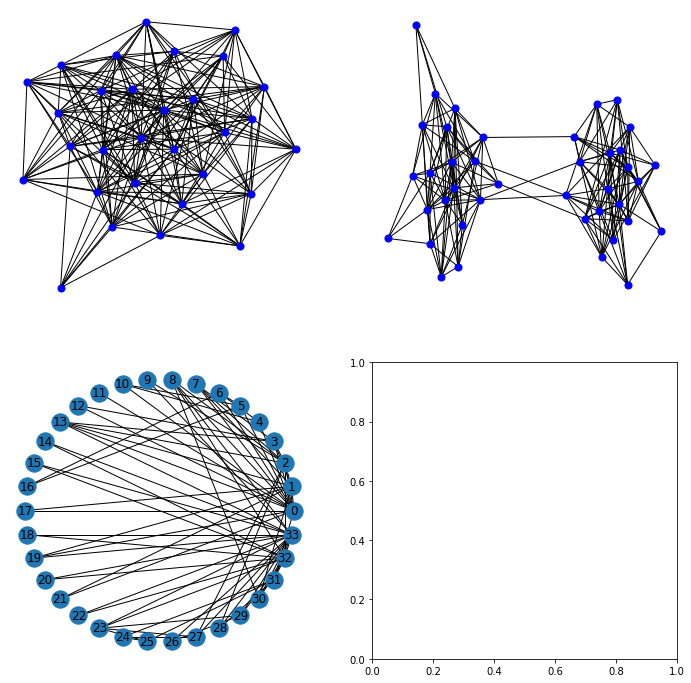

In [6]:
# Lets look at a few basic graphs, and then we'll discuss their properties
G1 = nx.erdos_renyi_graph(30,0.5)
pos1 = nx.drawing.spring_layout(G1)
G2 = nx.stochastic_block_model([20,20],[[0.5,0.01],[0.01,0.5]])
pos2 = nx.drawing.spring_layout(G2)
G3 = nx.karate_club_graph()

# plotting
fig, ax = plt.subplots(2,2,figsize=(12,12))
plt.sca(ax[0,0])
nx.draw(G1, pos1, node_color='b', node_size=50, with_labels=False)
plt.sca(ax[0,1])
nx.draw(G2, pos2, node_color='b', node_size=50, with_labels=False)
plt.sca(ax[1,0])
nx.draw_circular(G3, with_labels=True)

## Graph Terminology
- Vertices/Nodes. Will usually refer to them as $v_i$. 
- Edges (Directed/Undirected). $(i,j)$ denotes an edge from $v_i$ to $v_j$.
- Degree of a vertex = number of edges incident to it. Usually use notation $d_i$
- A simple path is a sequence of distinct vertices connected by edges. Vertices and therefore edges are not allowed to repeat.
- A walk is a sequence of vertices connected by edges.
- A cluster is a set of densely connected vertices, with few connections to the rest of the graph. Also called *communities* or *modules*

### Matrices associated to a graph
- Adjacency matrix: $\displaystyle A_{ij} = \left\{\begin{array}{cc} 1 & \text{ if } v_i \text{ is connected to } v_j \\ 0 & \text{ otherwise} \end{array}\right.$
- **Note:** If $G$ is undirected then $A$ is symmetric. Makes finding (and interpreting) eigenvalues and eigenvectors easy.
- Weighted adjacency matrix: $A_{ij} = w_{ij}$ where $w_{ij}$ is a notion of 'strength of connection' between $v_i$ and $v_j$. 
- Note that $\displaystyle d_i = \sum_{j=1}^{n} A_{ij}$
- Laplacian matrix (comes later)

## Centrality 
- **Question:** Which vertex in a graph is most important?

### Degree Centrality
- *Degree centrality:* Vertex with largest degree is most important.
    - $d_i = \#\{ \text{ length 1 walks passing through } v_i\}$
    - What about longer walks?

### Another measure of Centrality (from textbook)
- **Main Idea:** Consider longer walks. Most important vertex is on the most walks.
- **Claim** $A^{k}$ counts length $k$ walks
     - $(A^{k})_{ij} = \#\left\{ \text{ length $k$ walks from $v_i$ to $v_j$ }\right\}$
     - **Observe** $(A^{2})_{ii} = d_{i}$
- **Idea** $(A^{k})_{ii}$ generalizes the degree.
- Want to consider all of these generalizations --> Take sum
- Discounting: Longer walks should count for less:
     
$ I + A + \frac{A^{2}}{2!} + \frac{A^{3}}{3!} + \frac{A^{4}}{4!} + \ldots = \exp(A)$ 
     
- **Centrality** $\text{cent}(i) = (\exp(A))_{ii}$
- **Communicability:** $\text{com}(i,j) = (\exp(A))_{ij}$
- **Remark** Can compute matrix exponential fairly easily
 

## Spectral Clustering
- **Goal:** Partition vertex set $V$ into $k$ clusters: $V = V_1\cup \ldots \cup V_k$. 
- **To think about** 
    - What if we want clusters to overlap?
    - What if we only want to find one cluster?

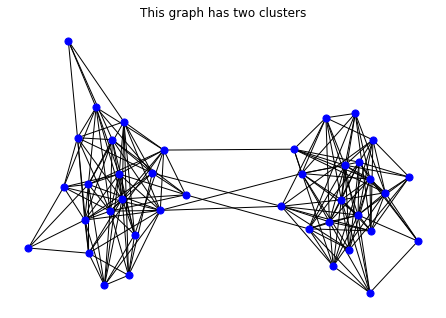

In [7]:
nx.draw(G2, pos2, node_color='b', node_size=50, with_labels=False)
plt.title('This graph has two clusters')
plt.show()

### Intuition for Spectral Clustering 
In the next three blocks we'll develop the intuition for spectral clustering. The high level idea is that the second eigenvector precisely defines connected components, and so approximately defines clusters. 


 - *We'll focus on the $k=2$ case*
 - Define Graph Laplacian $L = D - A$ where $D = \text{diag}[d_1,d_2,\ldots, d_n]\in\mathbb{R}^{n\times n}$
 - Let $\mathbf{1}\in\mathbb{R}^{n}$ denote the all-ones vector.
 - This matrix always has $0$ as an eigenvalue: $L\mathbf{1} = 0$. *(Will check this for Homework)*
 
At this stage the following two definitions are useful:

**Definition:** Given a subset of vertices $S\subset V$, define its *indicator vector* $\mathbf{1}_{S}$ with entries $\left(\mathbf{1}_{S}\right)_{i} = \left\{\begin{array}{cc} 1 & \text{ if } v_i\in S \\ 0 & \text{ otherwise } \end{array}\right.$ 

**Definition:** We say $S_1\subset V$ is a connected component of $G$ if there are no edges between vertices in $S_1$ and vertices in $S_2 = V\setminus S_1$. 

**Theorem** If $S_1$ and $S_2$ are connected components of $G$ then $\mathbf{1}_{S_1}$ and $\mathbf{1}_{S_2}$ are both eigenvectors for $L$ with eigenvalue $0$:

$ \displaystyle L\mathbf{1}_{S_1} = 0 \text{ and } L\mathbf{1}_{S_2} = 0 \quad \quad $ 


-The above shows that $\left\{\mathbf{1}_{S_1},\mathbf{1}_{S_2}\right\}$ form a basis for $0$-eigenspace (*i.e.* the kernel)
- Observe that $\mathbf{1} = \mathbf{1}_{S_1} + \mathbf{1}_{S_2}$.
- Usually easier to work with the basis $\{\mathbf{1},\mathbf{1}_{S_1} - \mathbf{1}_{S_2}\}$ 

**Simple Algorithm for finding connected components**
1. Form $L = D - A$.
2. Find a basis for $0$-eigenspace, $\{\mathbf{v}_1,\mathbf{v}_2\}$. Make sure that $\mathbf{v}_{1} = \mathbf{1}$.
3. Examine $\mathbf{v}_2$. Assign vertices using following rule:

$ \displaystyle v_i \in S_1 \text{ if }(\mathbf{v}_2)_{i} = 1\quad $ or $\quad \displaystyle v_i \in S_2 \text{ if } (\mathbf{v}_2)_{i} = -1$ 

*From connected components to clusters*
 - Suppose $S_1$ and $S_2$ are now clusters.
 - Few edges between $S_1$ and $S_2$ so 'approximately' connected components.
 - This means that $\lambda_2 \approx 0$ and $\mathbf{v}_2 \approx \mathbf{1}_{S_1} - \mathbf{1}_{S_2}$. 

**Spectral Clustering Algorithm**
1. Compute $L = D - A$
2. Compute $\lambda_2$ and $\mathbf{v}_2$
3. Assign vertices to clusters as:

$ \displaystyle v_i \in S_1 \text{ if }(\mathbf{v}_2)_{i} > 0\quad $ or $\quad \displaystyle v_i \in S_2 \text{ if } (\mathbf{v}_2)_{i} < 0$

**Remarks**
- If $S_1$ and $S_2$ are good clusters, then $\lambda_2 \approx 0$.
- Extension to finding $k > 2$ clusters is possible, but a little more tricky.
- In practice typically use the normalized random walk Laplacian: $L_{rw} = D^{-1}L = I - D^{-1}A$ or normalized symmetric Laplacian: $L_{sym} = D^{-1/2}LD^{-1/2} = I - D^{-1/2}AD^{-1/2}$

**Downfalls of Spectral Clustering**
- Finding eigenvectors is at least $O(n^2)$.
- Can fail when $|S_1|$ is much larger than $|S_2|$.
- Can fail when $\min_{i}d_{i}$ much smaller than $\max_{i}d_i$.
- *(For graphs with many clusters)* Spectral Clustering unable to pick out a single cluster---has to find all $k$

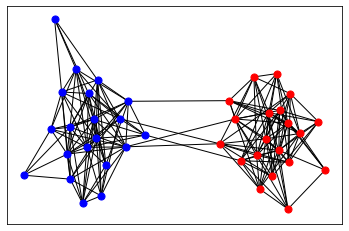

In [8]:
#### Lets do an example
# Step 1: Make the Laplacian
#A2 = nx.adjacency_matrix(G2)
A2 = nx.to_numpy_matrix(G2)
degrees = np.sum(A2,axis = 1)
D2 = np.diagflat(degrees,k=0)
L = D2 - A2
EigVals, Eigvecs = np.linalg.eig(L)
#print(Eigvecs[:,0])
#print(Eigvecs[:,1])
Feidler_vec = Eigvecs[:,1]

ClusterIndicator = np.zeros([40,1])
for i in range(40):
    if Feidler_vec[i] > 0:
        ClusterIndicator[i] = 1
    else:
        ClusterIndicator[i] = 0
#print(ClusterIndicator)
S1 = np.ndarray.tolist(np.where(ClusterIndicator)[0])
S2 = np.ndarray.tolist(np.where(ClusterIndicator == 0)[0])
#print(S2)
nx.draw_networkx_nodes(G2,pos2,nodelist = S1,node_color = 'r',node_size=50)
nx.draw_networkx_nodes(G2,pos2,nodelist = S2,node_color = 'b',node_size=50)
nx.draw_networkx_edges(G2,pos2)

The cell above shows the output of spectral clustering. As one can see, it perfectly detects the two clusters.

## Analysis of Spectral Clustering
*In this cell we'll go a bit deeper into the reasons why spectral clustering works. Throughout let $G = (V,E)$ with adjacency matrix $A$ and Laplacian $L$. We'll focus on the two cluster case.*

- Intuitively, a cluster has many internal edges and few external edges. How do we formalize this?
- **Boundary:** For any $S\subset V$ let $\partial S := \{ (i,j)\in E: \ i\in S \text{ and } j \notin S\}$
- **Cut:** Define $\text{Cut}(S) = |\partial S|$. 
- **Attempt at Clustering:** Let $S_1 = \text{argmin}_{S\subset V}\text{Cut}(S)$.
- Discussion
- **Ratio Cut** $\displaystyle \text{RCut}(S) = \frac{|\partial S|}{|S||S^{c}|}$
- **Better attempt at clustering:** Let $S_1 = \text{argmin}_{S\subset V}\text{RCut}(S)$.
- Discussion

## Analysis of Spectral Clustering Continued
- For any $S\subset V$ define $\mathbf{I}_{S}\in\mathbb{R}^{n}$ as $\displaystyle \mathbf{I}_{s} = \left\{\begin{array}{cc} \sqrt{\frac{|S^{c}|}{|S|}} & \text{ if } v_i \in S \\ -\sqrt{\frac{|S|}{|S^{c}|}} & \text{ if } v_i \notin S \end{array}\right. $ 
- **Properties of these indicator vectors**
    1. *Homework:* 
 \begin{align}
 \text{Rcut}(S) = \frac{1}{n^{2}} \mathbf{I}_{S}^{\top}L\mathbf{I}_{S}
 \end{align}
 *Recall that $n = |V|$ is the number of vertices*
    2. $\mathbf{1}^{\top}\mathbf{I}_{S} = 0$ Check:

$\displaystyle \mathbf{1}^{\top}\mathbf{I}_{S} = \sum_{i\in V}\left(\mathbf{I}_{S}\right)_{i} = \sum_{v_i\in S}\left(\sqrt{\frac{|S^{c}|}{|S|}}\right) + \sum_{v_i\in S^{c}}\left(-\sqrt{\frac{|S|}{|S^{c}|}}\right) = |S|\left(\sqrt{\frac{|S^{c}|}{|S|}}\right)  - |S^{c}|\left(\sqrt{\frac{|S|}{|S^{c}|}}\right) = \sqrt{|S||S^{c}|} - \sqrt{|S||S^{c}|} = 0$ 

    3.*Homework:* 
 \begin{align}
 \|\mathbf{I}_{S}\|_{2} = \sqrt{n}
 \end{align}
- So $S_1 = \text{argmin}_{S\subset V}\text{RCut}(S) \Leftrightarrow \mathbf{I}_{S_1} = \text{argmin}\left\{ \mathbf{v}^{\top}L\mathbf{v}: \ \mathbf{1}^{\top}\mathbf{v} = 0, \ \|\mathbf{v}\|_2 = \sqrt{n} \text{ and } \mathbf{v} = \mathbf{I}_{S} \text{ for some } S\subset V \right\}$ 
- However, this problem is still **NP-Hard**. 
- One possible fix: relaxation. Essentially, drop the constraint that is hardest to satisfy:

\begin{align}
\mathbf{I}_{S_1} \approx \text{argmin}\left\{ \mathbf{v}^{\top}L\mathbf{v}: \ \mathbf{1}^{\top}\mathbf{v} = 0, \ \|\mathbf{v}\|_2 = \sqrt{n}\right\}
\end{align}

- **Note** This problem has an elegant solution:
\begin{align}
\sqrt{n}\mathbf{v}_2 = \text{argmin}\left\{ \mathbf{v}^{\top}L\mathbf{v}: \ \mathbf{1}^{\top}\mathbf{v} = 0, \ \|\mathbf{v}\|_2 = \sqrt{n}\right\}
\end{align}

where $\mathbf{v}_2$ is second eigenvector of $L$ normalized to $\|\mathbf{v}_2\|_2 = 1$.

- So $\mathbf{v}_2 \approx \mathbf{I}_{S_1}$. Thus:
$$
v_i \in S_1 \text{ if } (\mathbf{v}_2)_i > 0 \text{ and } v_i \in S_1^{c} \text{ if } (\mathbf{v}_2)_{i} < 0 
$$
- **Big question:** How good is the approximation $\mathbf{v}_2 \approx \mathbf{I}_{S_1}$?
- **Further Reading:** *A Tutorial on Spectral Clustering* by Ulrike Von Luxburg.